# Electrophysiology Data, End to End

**What this notebook is.** A working introduction to cardiac electrophysiology
(EP) data: what it physically is, how it is turned into the coloured 3D heart
maps you see in an EP lab, and — just as important — how much of those maps is
measurement and how much is inference.

Everything here runs on **real clinical data**: two CARTO exports distributed
with the [OpenEP](https://openep.io) project, from catheter ablation procedures.

**How to read it.** Every quantity is labelled:

- **Measured** — recorded by the mapping system.
- **Derived** — computed here from measured data.
- **Illustrative** — a demonstration of a method the data cannot fully support.

**A note on the library.** We use `openep-py` to load the data and as a
correctness check, but the analysis is written out explicitly with numpy and
scipy. The point is to see the mathematics, not to call an API.

In [4]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import plotly.graph_objects as go
import pyvista as pv
import scipy.io
from scipy import spatial

import epkit
from epkit import clean_lat, load_case, mesh_to_plotly, plotly_figure

warnings.filterwarnings("ignore", category=UserWarning)
np.set_printoptions(precision=3, suppress=True)

case = load_case(1)          # primary dataset: has the ablation lesion tags
case2 = load_case(2)         # secondary, used for comparison

# A few fields we need later are dropped by the OpenEP loader, so keep the raw
# MATLAB structure to hand as well.
raw = scipy.io.loadmat(str(epkit.DATA_DIR / "openep_dataset_1.mat"))

print(case)

openep_dataset_1.mat( nodes: (9279, 3) indices: (10296, 3) fields: ('bipolar_voltage', 'unipolar_voltage', 'local_activation_time', 'impedance', 'force', 'thickness', 'cell_region', 'longitudinal_fibres', 'transverse_fibres', 'pacing_site') )


## Part 0 — What is actually in the file

An EP study export is three things bolted together: a **geometry** (the shell),
a set of **electrical recordings** (the points), and a record of **therapy
delivered** (the ablation). Everything else is derived from those.

In [5]:
electric = case.electric

summary = [
    ("Geometry: vertices",         case.points.shape[0]),
    ("Geometry: triangles",        case.indices.shape[0]),
    ("Mapping points",             electric.n_points),
    ("Samples per electrogram",    electric.n_samples),
    ("Sampling frequency (Hz)",    electric.frequency),
    ("Recording duration (s)",     electric.n_samples / electric.frequency),
    ("Bipolar electrogram array",  electric.bipolar_egm.egm.shape),
    ("Unipolar electrogram array", electric.unipolar_egm.egm.shape),
    ("ECG array",                  electric.ecg.ecg.shape),
    ("Ablation samples",           len(case.ablation.times)),
]
width = max(len(label) for label, _ in summary)
for label, value in summary:
    print(f"{label:<{width}} : {value}")

Geometry: vertices         : 9279
Geometry: triangles        : 10296
Mapping points             : 1366
Samples per electrogram    : 2500
Sampling frequency (Hz)    : 1000.0
Recording duration (s)     : 2.5
Bipolar electrogram array  : (1366, 2500)
Unipolar electrogram array : (1366, 2500, 2)
ECG array                  : (1366, 2500, 1)
Ablation samples           : 17258


Note the shape of the problem. There are **1,366 electrical recordings** but
**9,279 geometry vertices**. Every coloured map you will ever see in an EP lab is
an interpolation from the former onto the latter — roughly seven vertices coloured
for every one actually measured. Part 4 takes that seriously.

## Part 1 — What EP data physically is

### The cell

A cardiac myocyte holds roughly **-85 mV** across its membrane at rest, set by
ion pumps maintaining concentration gradients. The membrane is studded with
voltage-gated ion channels — conductances that open and close as a function of
the very voltage they control.

That feedback is the whole story. Depolarise the membrane past about -65 mV and
sodium channels open, admitting Na⁺, depolarising it further, opening more
channels. The result is a near-instantaneous upstroke to about +20 mV: the
**action potential**. Calcium channels sustain a plateau (this is what makes
cardiac action potentials last ~200-300 ms rather than the ~1 ms of a neuron),
then potassium channels repolarise the cell.

For an engineer: it is a relaxation oscillator with a refractory period, and the
refractory period is what stops the heart from simply oscillating uncontrollably.

### The tissue

Myocytes are electrically coupled through gap junctions, so a cell reaching
threshold drags its neighbours with it. The tissue is an **excitable medium**: a
depolarisation wavefront propagates outward at roughly **0.3-1.0 m/s**, and
behind it the refractory tail leaves tissue briefly unexcitable.

Arrhythmia is what happens when that wave misbehaves. If a wavefront finds a path
back to tissue that has recovered, it re-excites it, and you have **reentry** — a
self-sustaining circuit. Diseased tissue conducts slowly, which makes reentry
easier, because slow conduction gives tissue ahead of the wave time to recover.
This is why the slow-conduction regions we map in Part 7 matter clinically.

### The measurement

A moving wavefront is a moving boundary between depolarised and resting tissue —
a travelling charge separation, which produces a **potential field in the blood
and tissue around it**. An electrode in the chamber samples that field.

This is the key point: the catheter does **not** measure the action potential of
any cell. It measures the extracellular field produced by many cells depolarising
together. What you get is roughly proportional to the *rate of change* of nearby
transmembrane potential, weighted by 1/distance. So:

- Fast, synchronous depolarisation nearby → a large sharp deflection.
- Slow or disorganised depolarisation → a small, smeared, fragmented signal.
- Dead scar tissue → almost nothing, just far-field signal from elsewhere.

That relationship is what makes the whole enterprise work: **signal amplitude
becomes a proxy for tissue health, and deflection timing becomes a proxy for when
the wave arrived.**

In [6]:
# MEASURED. One electrogram, and what the sampling actually looks like.
fs = electric.frequency
times_ms = np.arange(electric.n_samples) / fs * 1000.0

point = 500
bipolar = electric.bipolar_egm.egm[point]

print(f"Point label      : {electric.internal_names[point]}")
print(f"Sampling         : {fs:.0f} Hz -> {1000 / fs:.1f} ms per sample")
print(f"Duration         : {times_ms[-1] / 1000:.2f} s")
print(f"Amplitude range  : {bipolar.min():.3f} to {bipolar.max():.3f} mV")

Point label      : P797
Sampling         : 1000 Hz -> 1.0 ms per sample
Duration         : 2.50 s
Amplitude range  : -1.548 to 0.516 mV


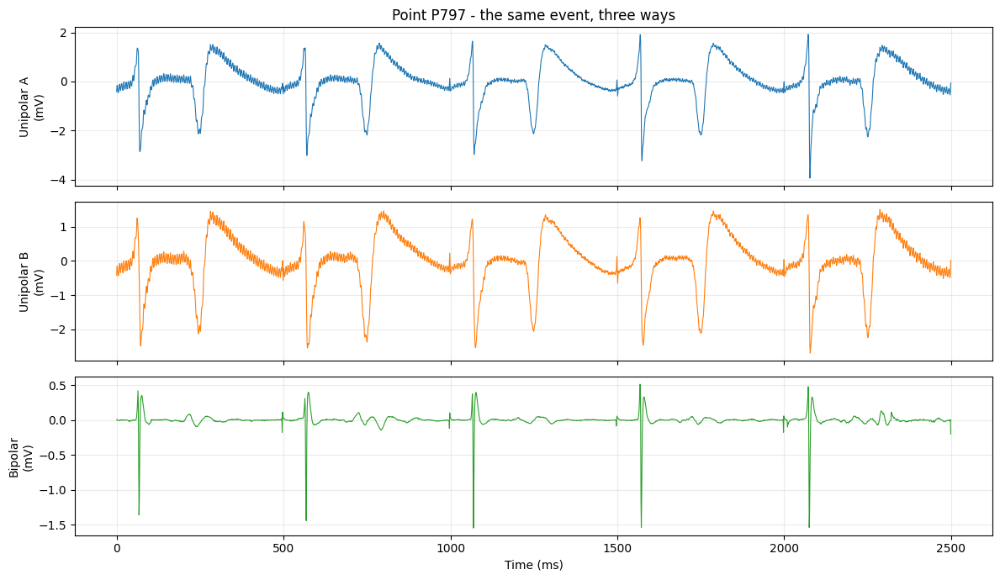

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)

axes[0].plot(times_ms, electric.unipolar_egm.egm[point, :, 0], lw=0.8, color="#1f77b4")
axes[0].set_ylabel("Unipolar A\n(mV)")
axes[0].set_title(f"Point {electric.internal_names[point]} - the same event, three ways")

axes[1].plot(times_ms, electric.unipolar_egm.egm[point, :, 1], lw=0.8, color="#ff7f0e")
axes[1].set_ylabel("Unipolar B\n(mV)")

axes[2].plot(times_ms, bipolar, lw=0.8, color="#2ca02c")
axes[2].set_ylabel("Bipolar\n(mV)")
axes[2].set_xlabel("Time (ms)")

for ax in axes:
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Part 2 — The electrogram up close

### Unipolar vs bipolar: a spatial high-pass filter

A **unipolar** recording measures one electrode against a distant reference. It
sees local activity, but also everything else in the heart — *far-field* signal.

A **bipolar** recording is the difference between two closely spaced electrodes.
Distant sources affect both electrodes almost equally, so subtracting cancels
them; local sources affect them differently, so local signal survives.

In signal-processing terms, subtracting two spatially offset samples of a field
is a **discrete spatial derivative** — a high-pass filter in space. It buys
locality at a price we will pay in Part 6: the output depends on the *direction*
the wavefront crosses the electrode pair.

The textbook statement is that bipolar *is* that difference. The file lets us
test it rather than take it on faith — so let us actually test it.

In [8]:
# DERIVED. Test the textbook claim: is bipolar exactly uniA - uniB?
uni_a = electric.unipolar_egm.egm[:, :, 0]
uni_b = electric.unipolar_egm.egm[:, :, 1]
derived_bipolar = uni_a - uni_b
stored_bipolar = electric.bipolar_egm.egm

per_point_corr = np.array([
    np.corrcoef(derived_bipolar[i], stored_bipolar[i])[0, 1]
    if np.std(derived_bipolar[i]) > 0 and np.std(stored_bipolar[i]) > 0 else np.nan
    for i in range(electric.n_points)
])

print(f"median per-point correlation : {np.nanmedian(per_point_corr):.3f}")
print(f"points correlating > 0.99    : {int(np.nansum(per_point_corr > 0.99))} of {electric.n_points}")
print()
print("amplitude check (99th percentile of |signal|):")
print(f"  stored bipolar    : {np.nanpercentile(np.abs(stored_bipolar), 99):.2f} mV")
print(f"  uniA - uniB       : {np.nanpercentile(np.abs(derived_bipolar), 99):.2f} mV")
print(f"  ratio             : {np.nanpercentile(np.abs(derived_bipolar), 99) / np.nanpercentile(np.abs(stored_bipolar), 99):.2f}")
print(f"  single unipolar   : {np.nanpercentile(np.abs(uni_a), 99):.2f} mV  <- far-field included")

median per-point correlation : 0.495
points correlating > 0.99    : 0 of 1366

amplitude check (99th percentile of |signal|):
  stored bipolar    : 0.62 mV
  uniA - uniB       : 0.68 mV
  ratio             : 1.09
  single unipolar   : 2.69 mV  <- far-field included


**The textbook claim does not survive contact with the file.** The correlation is
about 0.5, and essentially no point matches cleanly.

But look at the amplitude row: the difference is within about 10% of the stored
bipolar's scale, while a *single* unipolar channel is four times larger. So the
subtraction is doing exactly what the theory says — cancelling the large shared
far-field component and leaving a small local signal. The physics is right; the
arithmetic identity is not.

Why? Because the two channels travel different processing paths before export.
Bipolar channels are band-pass filtered (typically ~30-400 Hz) to sharpen local
deflections, while unipolar channels keep much more low-frequency content. Let us
check how much of the gap that explains.

In [9]:
# DERIVED. Does matching the filtering close the gap?
from scipy import signal as sps

def median_correlation(candidate, n=400):
    scores = [
        np.corrcoef(candidate[i], stored_bipolar[i])[0, 1]
        for i in range(n) if np.std(candidate[i]) > 0
    ]
    return np.nanmedian(scores)

print(f"{'signal compared against stored bipolar':<42}{'median correlation':>20}")
print(f"{'uniA - uniB, unfiltered':<42}{median_correlation(derived_bipolar):>20.3f}")
for low, high in [(10, 400), (30, 300), (30, 400)]:
    b, a = sps.butter(2, [low / (fs / 2), high / (fs / 2)], btype="bandpass")
    filtered = sps.filtfilt(b, a, derived_bipolar, axis=1)
    print(f"{f'uniA - uniB, band-pass {low}-{high} Hz':<42}{median_correlation(filtered):>20.3f}")

signal compared against stored bipolar      median correlation
uniA - uniB, unfiltered                                  0.508
uniA - uniB, band-pass 10-400 Hz                         0.589
uniA - uniB, band-pass 30-300 Hz                         0.614
uniA - uniB, band-pass 30-400 Hz                         0.600


Filtering moves it from roughly 0.51 to 0.61 — real, but it does not close the
gap. (Allowing an optimal time shift per point gets to about 0.78, and only 14%
of points exceed 0.9, so this is not a simple clock offset either.)

**The lesson is the useful part.** A clinical export is not a set of arithmetically
consistent arrays. Each channel has been through vendor-specific filtering, gain,
and annotation logic that is not documented in the file. The conceptual
relationship — bipolar is a local spatial difference — holds and is what makes
bipolar useful. The literal one is not something you can rely on.

So: **verify relationships in the data rather than assuming them from theory.**
Every later part of this notebook computes from the stored bipolar signal, which
is the channel the clinical measurements were actually derived from.

### Timing: the reference, the window, and the annotation

A single electrogram tells you a wave arrived, not *when* in the cardiac cycle.
Timing is only meaningful relative to a fixed fiducial, so every point is timed
against a **reference channel** — typically a stable intracardiac electrode.

Three numbers per point:

- `referenceAnnot` — the fiducial on the reference channel (2000 samples here).
- `mapAnnot` — the moment of local activation at this point.
- `woi` — the **window of interest**, the slice of the recording that is allowed
  to contain valid activation.

**Local activation time** is the difference. And here is a trap that will silently
ruin a map.

In [10]:
# MEASURED, then cleaned. Unannotated points carry a -10000 sentinel.
annotations = electric.annotations
raw_lat = annotations.local_activation_time - annotations.reference_activation_time

print(f"raw LAT range     : {raw_lat.min():.0f} to {raw_lat.max():.0f} ms")
print(f"sentinel points   : {int(np.sum(raw_lat <= -1000))} of {raw_lat.size}")

lat, valid = clean_lat(
    annotations.local_activation_time, annotations.reference_activation_time
)
print(f"cleaned LAT range : {np.nanmin(lat):.0f} to {np.nanmax(lat):.0f} ms")
print()
print(f"mean WITH sentinels    : {raw_lat.mean():>10.1f} ms   <- meaningless")
print(f"mean WITHOUT sentinels : {np.nanmean(lat):>10.1f} ms   <- correct")

raw LAT range     : -10000 to 121 ms
sentinel points   : 22 of 1366
cleaned LAT range : 24 to 121 ms

mean WITH sentinels    :      -89.1 ms   <- meaningless
mean WITHOUT sentinels :       73.1 ms   <- correct


Twenty-two points out of 1,366 — 1.6% of the data — drag the naive mean to a
physically impossible value. Any statistic, interpolation, or colour scale
computed without masking them is wrong, and wrong in a way that still produces a
plausible-looking picture. **This is the single most common way to silently
corrupt an activation map.**

### Re-annotating it ourselves

The mapping system chose `mapAnnot` for us. On a bipolar electrogram, activation
is conventionally annotated at the **peak absolute amplitude** or the steepest
deflection. Let us apply that rule ourselves and see how far we land from the
system.

In [11]:
# DERIVED. Re-annotate by steepest deflection within the window of interest.
woi = annotations.window_of_interest
reference_annotation = annotations.reference_activation_time

our_lat = np.full(electric.n_points, np.nan)
for i in range(electric.n_points):
    start = int(reference_annotation[i] + woi[i, 0])
    stop = int(reference_annotation[i] + woi[i, 1])
    start, stop = max(start, 0), min(stop, electric.n_samples)
    if stop - start < 3:
        continue
    segment = stored_bipolar[i, start:stop]
    our_lat[i] = start + int(np.argmax(np.abs(np.gradient(segment)))) - reference_annotation[i]

both = valid & np.isfinite(our_lat)
difference = our_lat[both] - lat[both]
print(f"points compared      : {both.sum()}")
print(f"median difference    : {np.median(difference):>7.1f} ms")
print(f"IQR                  : {np.percentile(difference, 25):.1f} to {np.percentile(difference, 75):.1f} ms")
print(f"within +/-5 ms       : {np.mean(np.abs(difference) <= 5) * 100:.1f}%")

points compared      : 1344
median difference    :     0.0 ms
IQR                  : -1.0 to 1.0 ms
within +/-5 ms       : 91.4%


The annotation rule is a **choice**, and the choice moves the map. Where the
electrogram is a single sharp spike, every rule agrees. Where it is fragmented —
exactly the diseased tissue we most want to characterise — rules disagree by tens
of milliseconds. That uncertainty propagates into every downstream map.

## Part 3 — The shell: where the geometry comes from

The coloured heart you see on an EP screen is a **triangulated surface mesh**
built during the procedure, not a scan. The operator sweeps the catheter around
the inside of the chamber and the system accumulates the outermost positions the
catheter reached — **fast anatomical mapping (FAM)**. The shell is, literally, the
envelope of where the catheter has been.

Two consequences follow, and both matter:

1. **Unvisited regions do not exist.** The mesh cannot represent anatomy the
   catheter never touched.
2. **The geometry and the electrical data are sampled at completely different
   densities.** FAM produces thousands of vertices; electrical points number in
   the hundreds. They are separate acquisitions.

In [12]:
# MEASURED / DERIVED. Mesh resolution vs electrical sampling density.
points, triangles = case.points, case.indices

edges = np.vstack([
    triangles[:, [0, 1]], triangles[:, [1, 2]], triangles[:, [2, 0]]
])
edge_lengths = np.linalg.norm(points[edges[:, 0]] - points[edges[:, 1]], axis=1)

tri_pts = points[triangles]
areas = 0.5 * np.linalg.norm(
    np.cross(tri_pts[:, 1] - tri_pts[:, 0], tri_pts[:, 2] - tri_pts[:, 0]), axis=1
)

egm_points = electric.bipolar_egm.points
tree = spatial.cKDTree(egm_points)
nn_distance = tree.query(egm_points, k=2)[0][:, 1]

print(f"Mesh vertices            : {len(points):,}")
print(f"Mesh triangles           : {len(triangles):,}")
print(f"Total surface area       : {areas.sum():,.0f} mm^2")
print(f"Median mesh edge length  : {np.median(edge_lengths):.2f} mm   <- FAM resolution")
print()
print(f"Electrical points        : {len(egm_points):,}")
print(f"Median point-to-point    : {np.median(nn_distance):.2f} mm   <- nearest neighbour")
print()
print(f"Vertices per point       : {len(points) / len(egm_points):.1f}")
print(f"Area per electrical point: {areas.sum() / len(egm_points):.0f} mm^2")

Mesh vertices            : 9,279
Mesh triangles           : 10,296
Total surface area       : 11,096 mm^2
Median mesh edge length  : 1.56 mm   <- FAM resolution

Electrical points        : 1,366
Median point-to-point    : 1.49 mm   <- nearest neighbour

Vertices per point       : 6.8
Area per electrical point: 8 mm^2


The first surprise: median mesh edge and median point-to-point spacing are
almost identical, around 1.5 mm. It is tempting to conclude the two acquisitions
are equally well resolved. **That conclusion would be wrong**, and the reason is
worth dwelling on.

Nearest-neighbour distance measures how close points are *to each other*, not how
well they cover the surface. A multi-electrode catheter drops ten points at once
in a tight cluster, so the nearest neighbour is always close by — even if the
whole cluster sits in a region already densely sampled and half the chamber has
never been touched.

The metric that actually matters is the reverse question: **for each vertex, how
far away is the nearest real measurement?** That is what decides whether a vertex
can be honestly coloured.

distance from each vertex to the nearest electrical measurement:
  10th percentile :   0.00 mm
  25th percentile :   1.38 mm
  50th percentile :   3.16 mm
  75th percentile :   9.44 mm
  90th percentile :  17.38 mm
  99th percentile :  26.90 mm

  vertices within  3 mm of a measurement :  48.6%
  vertices within  5 mm of a measurement :  61.1%
  vertices within 10 mm of a measurement :  76.3%
  vertices within 20 mm of a measurement :  92.9%


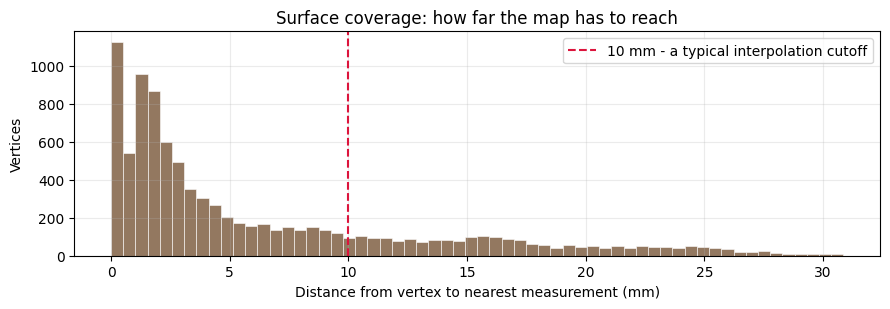

In [13]:
# DERIVED. Coverage measured from the surface's point of view.
surface_points = electric.surface.nearest_point
coverage_distance = spatial.cKDTree(surface_points).query(points, k=1)[0]

print("distance from each vertex to the nearest electrical measurement:")
for pct in (10, 25, 50, 75, 90, 99):
    print(f"  {pct:>2}th percentile : {np.percentile(coverage_distance, pct):6.2f} mm")
print()
for threshold in (3, 5, 10, 20):
    share = np.mean(coverage_distance <= threshold) * 100
    print(f"  vertices within {threshold:>2} mm of a measurement : {share:5.1f}%")

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.hist(coverage_distance, bins=60, color="#937860", edgecolor="white", lw=0.4)
ax.axvline(10, color="crimson", ls="--", label="10 mm - a typical interpolation cutoff")
ax.set_xlabel("Distance from vertex to nearest measurement (mm)")
ax.set_ylabel("Vertices")
ax.set_title("Surface coverage: how far the map has to reach")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

That is the real picture, and it is much less flattering than the 1.5 mm figure
suggested. Coverage is deeply uneven: some of the surface sits right next to a
measurement, and a substantial fraction is far from any. Those distant vertices
are the ones that will go grey in Part 4 — and the ones an over-eager
interpolator would happily colour in anyway.

**Nearest-neighbour spacing flatters clustered sampling.** It is the number most
easily quoted about a map and among the least informative.

### Where the catheter went: projection distance

Electrical points are recorded wherever the catheter tip was, which is near the
wall but not exactly on it. The system projects each point onto the mesh. That
projection distance is a quality signal: a point recorded far from the wall was
probably not in good contact.

median : 2.97 mm
p95    : 6.06 mm
max    : 6.98 mm


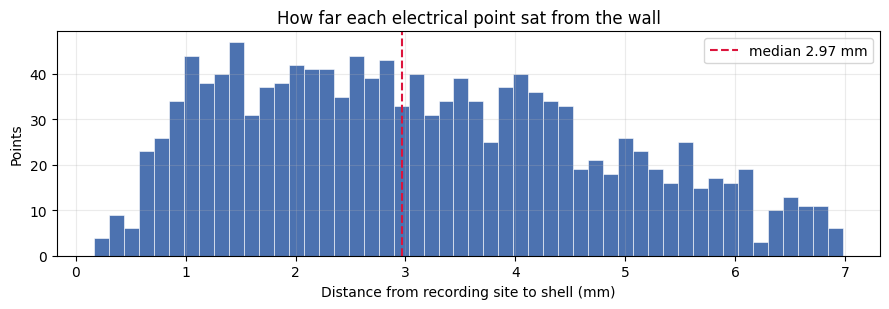

In [14]:
# MEASURED. Distance from recording position to its projection on the shell.
surface_points = electric.surface.nearest_point
projection_distance = np.linalg.norm(egm_points - surface_points, axis=1)

print(f"median : {np.nanmedian(projection_distance):.2f} mm")
print(f"p95    : {np.nanpercentile(projection_distance, 95):.2f} mm")
print(f"max    : {np.nanmax(projection_distance):.2f} mm")

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.hist(projection_distance, bins=50, color="#4c72b0", edgecolor="white", lw=0.4)
ax.axvline(np.nanmedian(projection_distance), color="crimson", ls="--",
           label=f"median {np.nanmedian(projection_distance):.2f} mm")
ax.set_xlabel("Distance from recording site to shell (mm)")
ax.set_ylabel("Points")
ax.set_title("How far each electrical point sat from the wall")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### The holes are anatomy

The shell is not a closed surface. Where the chamber opens into a vein or a
valve, the mesh simply ends, leaving a **free boundary** — an edge belonging to
only one triangle. Finding them is pure topology, and they identify real
anatomical structures.

For a left atrium we expect roughly six: the mitral valve (much the largest),
four pulmonary veins, and the left atrial appendage.

In [15]:
# DERIVED, cross-checked against OpenEP.
from collections import Counter

from openep.mesh.mesh_routines import get_free_boundaries

edge_keys = Counter()
for tri in triangles:
    for a, b in ((tri[0], tri[1]), (tri[1], tri[2]), (tri[2], tri[0])):
        edge_keys[(min(a, b), max(a, b))] += 1

our_boundary_edges = [edge for edge, count in edge_keys.items() if count == 1]
print(f"our boundary edges    : {len(our_boundary_edges)}")

mesh = case.create_mesh()
free_boundaries = get_free_boundaries(mesh)
separated = free_boundaries.separate_boundaries()
lengths = free_boundaries.calculate_lengths()
boundary_areas = free_boundaries.calculate_areas()

print(f"OpenEP boundary edges : {sum(len(b) for b in separated)}")
print(f"distinct boundaries   : {len(separated)}")
print()
order = np.argsort(lengths)[::-1]
print(f"{'#':<3}{'edges':>7}{'perimeter mm':>15}{'area mm^2':>12}   likely structure")
for rank, idx in enumerate(order):
    guess = "mitral valve" if rank == 0 else "pulmonary vein / appendage"
    print(f"{rank:<3}{len(separated[idx]):>7}{lengths[idx]:>15.1f}"
          f"{boundary_areas[idx]:>12.1f}   {guess}")

our boundary edges    : 578
OpenEP boundary edges : 578
distinct boundaries   : 6

#    edges   perimeter mm   area mm^2   likely structure
0      146          123.5      1076.8   mitral valve
1      117           81.8       439.3   pulmonary vein / appendage
2       92           70.5       360.7   pulmonary vein / appendage
3       67           62.0       261.3   pulmonary vein / appendage
4       84           61.6       277.0   pulmonary vein / appendage
5       72           50.8       186.3   pulmonary vein / appendage


Our raw edge count matches OpenEP's, and the structure is exactly what the anatomy
predicts: one large opening — the mitral valve — and five smaller ones for the
pulmonary veins and appendage. **We identified cardiac anatomy from nothing but
mesh connectivity.**

### The first render

Bare anatomy, no physiology yet. Two engines, as promised: PyVista gives a live
VTK view while the kernel runs, Plotly stays embedded in the saved file.

In [16]:
# Live PyVista/trame view.
epkit.show_pyvista(mesh, color="#c8a0a0", title="Left atrium - FAM shell")

Widget(value='<iframe src="http://localhost:35201/index.html?ui=P_0x79d662cb3e80_0&reconnect=auto" class="pyvi…

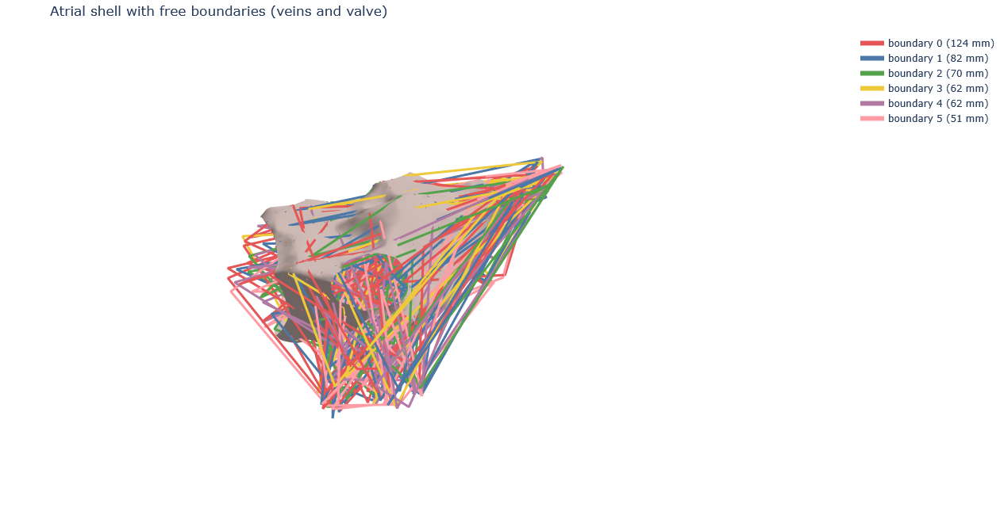

In [17]:
# Embedded Plotly view, with the free boundaries traced on top.
shell = mesh_to_plotly(points, triangles, name="atrial shell")

boundary_traces = []
palette = ["#e45756", "#4c78a8", "#54a24b", "#eeca3b", "#b279a2", "#ff9da6"]
for rank, idx in enumerate(order):
    ring = np.append(separated[idx][:, 0], separated[idx][0, 0])
    ring_points = points[ring]
    boundary_traces.append(
        go.Scatter3d(
            x=ring_points[:, 0], y=ring_points[:, 1], z=ring_points[:, 2],
            mode="lines", line=dict(width=6, color=palette[rank % len(palette)]),
            name=f"boundary {rank} ({lengths[idx]:.0f} mm)",
        )
    )

plotly_figure([shell, *boundary_traces],
              title="Atrial shell with free boundaries (veins and valve)").show()

## Part 4 — From points to maps: the interpolation problem

This is the heart of the matter. We have **1,366 measurements** and **9,279
vertices** to colour. Every vertex that was not measured gets a value invented by
an interpolator.

The standard approach is inverse-distance or radial-basis weighting: a vertex
takes a weighted average of nearby measurements, weighted by proximity. Crucially
it is also **distance-masked** — beyond some radius from any measurement, the
interpolator refuses to guess and returns NaN, leaving a hole in the map.

That refusal is the most honest thing the algorithm does.

In [18]:
# DERIVED. Inverse-distance interpolation with an explicit distance mask.
def interpolate_to_surface(sample_points, sample_values, target_points,
                           max_distance=10.0, k=8, power=2.0):
    """Inverse-distance weighted interpolation with a hard distance cutoff.

    Vertices with no sample within `max_distance` return NaN rather than a
    fabricated value.
    """
    finite = np.isfinite(sample_values)
    sample_points = sample_points[finite]
    sample_values = sample_values[finite]

    tree = spatial.cKDTree(sample_points)
    k = min(k, len(sample_points))
    distances, indices = tree.query(target_points, k=k)
    distances = np.atleast_2d(distances.T).T
    indices = np.atleast_2d(indices.T).T

    with np.errstate(divide="ignore"):
        weights = 1.0 / np.power(distances, power)
    weights[~np.isfinite(weights)] = 1e12          # exact hits dominate

    values = np.sum(weights * sample_values[indices], axis=1) / np.sum(weights, axis=1)
    values[distances[:, 0] > max_distance] = np.nan
    return values


vertex_lat = interpolate_to_surface(surface_points[valid], lat[valid], points)

print(f"vertices coloured : {np.isfinite(vertex_lat).sum():,} of {len(points):,}")
print(f"our map, NaN      : {np.isnan(vertex_lat).mean() * 100:.1f}%   (10 mm cutoff)")
print(f"OpenEP's own map  : {np.isnan(case.fields.local_activation_time).mean() * 100:.1f}% NaN")

vertices coloured : 7,079 of 9,279
our map, NaN      : 23.7%   (10 mm cutoff)
OpenEP's own map  : 41.5% NaN


The two disagree — 23.7% against 41.5% — and the disagreement is *entirely* our
choice of cutoff. OpenEP is stricter about how far it will reach from a
measurement than our 10 mm default.

We can recover the threshold OpenEP actually used, by sweeping ours until the
uncoloured fraction matches.

In [19]:
# DERIVED. Which cutoff reproduces OpenEP's coverage?
openep_nan = np.isnan(case.fields.local_activation_time).mean() * 100
vertex_gap = spatial.cKDTree(surface_points[valid]).query(points, k=1)[0]

print(f"{'cutoff':>8}{'NaN %':>10}")
for threshold in (3, 4, 5, 6, 8, 10):
    print(f"{threshold:>6} mm{np.mean(vertex_gap > threshold) * 100:>9.1f}")
print(f"\nOpenEP's actual  {openep_nan:>8.1f}   -> an effective cutoff near 4.5 mm")

  cutoff     NaN %
     3 mm     51.7
     4 mm     44.3
     5 mm     38.9
     6 mm     35.4
     8 mm     29.2
    10 mm     23.7

OpenEP's actual      41.5   -> an effective cutoff near 4.5 mm


So OpenEP will not colour a vertex more than roughly 4.5 mm from a real
measurement, and on that basis **two of every five vertices cannot be honestly
coloured at all**.

That number is not a property of the heart, the catheter, or the recording. It is
a threshold someone chose. Move it and the map's apparent completeness moves with
it, while the underlying measurements stay exactly the same.

### How much of the map is real?

Now the uncomfortable experiment. Same measurements, different reasonable
choices — and the resulting maps differ.

In [20]:
# DERIVED. The same data under three interpolation regimes.
from scipy.interpolate import griddata

variants = {
    "IDW, 10 mm mask": vertex_lat,
    "IDW, 30 mm mask": interpolate_to_surface(
        surface_points[valid], lat[valid], points, max_distance=30.0),
    "Nearest neighbour": griddata(
        surface_points[valid], lat[valid], points, method="nearest"),
}

for name, field in variants.items():
    coloured = np.isfinite(field).mean() * 100
    print(f"{name:<20} coloured {coloured:5.1f}%   "
          f"range {np.nanmin(field):6.1f} to {np.nanmax(field):6.1f} ms")

strict = variants["IDW, 10 mm mask"]
loose = variants["IDW, 30 mm mask"]
nearest = variants["Nearest neighbour"]

shared = np.isfinite(strict) & np.isfinite(loose)
invented = np.isnan(strict) & np.isfinite(loose)

print(f"\nwhere both are defined : median difference "
      f"{np.nanmedian(np.abs(strict[shared] - loose[shared])):.2f} ms")
print(f"vertices the 30 mm mask invents that 10 mm refused : "
      f"{invented.sum():,} ({invented.mean() * 100:.1f}% of the surface)")

shared_nn = np.isfinite(strict) & np.isfinite(nearest)
print(f"nearest-neighbour vs IDW, where both defined : median "
      f"{np.nanmedian(np.abs(strict[shared_nn] - nearest[shared_nn])):.2f} ms")

IDW, 10 mm mask      coloured  76.3%   range   24.0 to  121.0 ms
IDW, 30 mm mask      coloured  99.8%   range   24.0 to  121.0 ms
Nearest neighbour    coloured 100.0%   range   24.0 to  121.0 ms

where both are defined : median difference 0.00 ms
vertices the 30 mm mask invents that 10 mm refused : 2,180 (23.5% of the surface)
nearest-neighbour vs IDW, where both defined : median 1.61 ms


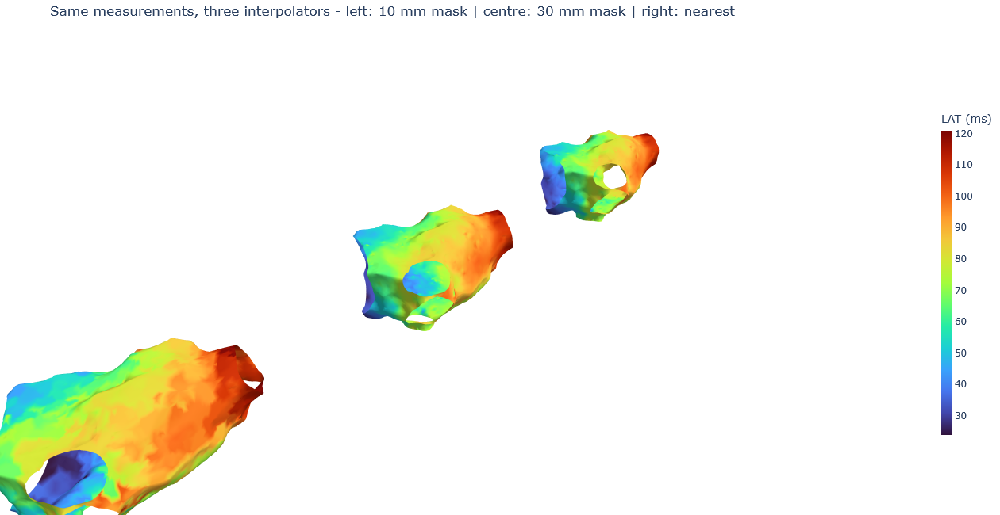

In [21]:
traces = []
for offset, (name, field) in enumerate(variants.items()):
    shifted = points.copy()
    shifted[:, 0] += offset * 145.0
    traces.append(mesh_to_plotly(
        shifted, triangles, scalars=field, colorscale="Turbo",
        cmin=np.nanmin(lat), cmax=np.nanmax(lat),
        name=name, showscale=(offset == 0), colorbar_title="LAT (ms)",
    ))

plotly_figure(traces, title="Same measurements, three interpolators - "
                           "left: 10 mm mask | centre: 30 mm mask | right: nearest").show()

Read that first number carefully: where both interpolators are willing to commit,
they agree **exactly**. Loosening the mask does not alter a single existing value.
What it changes is the quarter of the surface that the strict version left blank
and the loose version fills in — conjured from measurements up to 30 mm away.

That is the whole point. The left-hand map admits what it does not know. The
middle one is smoother, prettier, and partly fiction. The right-hand one is
confident everywhere and honest nowhere.

**None of these is more "correct" than the others.** They encode different
assumptions about how far a measurement's influence should reach. A clinician
reading a map is reading those assumptions as much as the tissue.

### Watching the map dissolve

What happens as measurements are thrown away?

 1344 points ->  76.3% coloured
  400 points ->  74.0% coloured
  150 points ->  62.0% coloured
   50 points ->  47.1% coloured


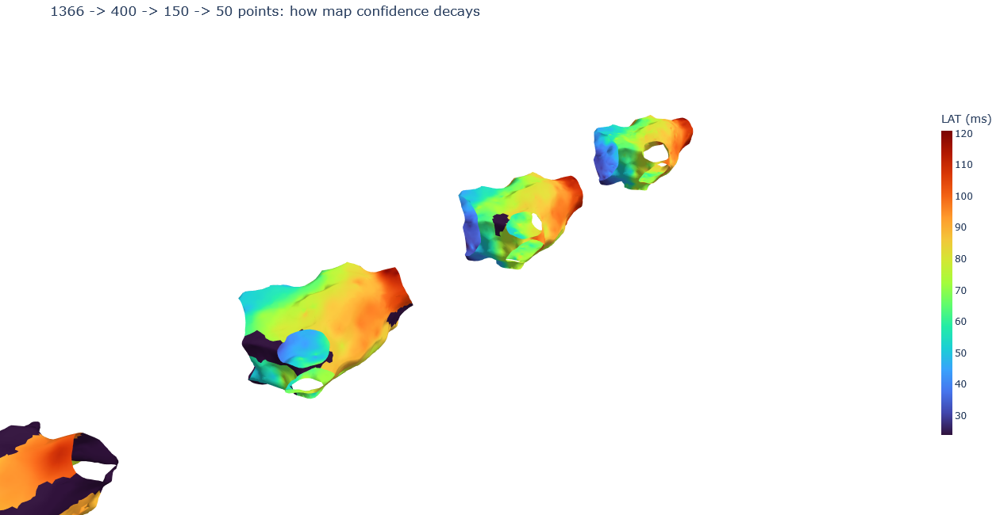

In [22]:
# DERIVED. Degrade the sampling density and watch the map degrade with it.
rng = np.random.default_rng(42)
valid_indices = np.flatnonzero(valid)

traces = []
for offset, n_keep in enumerate([len(valid_indices), 400, 150, 50]):
    keep = rng.choice(valid_indices, size=min(n_keep, len(valid_indices)), replace=False)
    field = interpolate_to_surface(surface_points[keep], lat[keep], points)

    shifted = points.copy()
    shifted[:, 0] += offset * 145.0
    traces.append(mesh_to_plotly(
        shifted, triangles, scalars=field, colorscale="Turbo",
        cmin=np.nanmin(lat), cmax=np.nanmax(lat),
        name=f"{len(keep)} points", showscale=(offset == 0), colorbar_title="LAT (ms)",
    ))
    print(f"{len(keep):>5} points -> {np.isfinite(field).mean() * 100:5.1f}% coloured")

plotly_figure(traces, title="1366 -> 400 -> 150 -> 50 points: how map confidence decays").show()

The overall pattern survives surprisingly far down. **Fine structure does not** —
and fine structure is exactly what identifies an arrhythmia circuit. A sparsely
sampled map can look perfectly convincing while having lost the thing you are
looking for.

## Part 5 — The activation map

Now the payoff. Colour the shell by **when** each region activated, and the
propagation pattern of the heartbeat becomes visible.

Convention: **red is early, blue is late.**

In [23]:
# DERIVED. Activation timing across the chamber.
earliest_vertex = int(np.nanargmin(vertex_lat))
latest_vertex = int(np.nanargmax(vertex_lat))

print(f"Earliest activation : {np.nanmin(vertex_lat):.0f} ms")
print(f"Latest activation   : {np.nanmax(vertex_lat):.0f} ms")
print(f"Total activation    : {np.nanmax(vertex_lat) - np.nanmin(vertex_lat):.0f} ms")
print(f"Spread across points: {np.nanmax(lat) - np.nanmin(lat):.0f} ms")

Earliest activation : 24 ms
Latest activation   : 121 ms
Total activation    : 97 ms
Spread across points: 97 ms


In [24]:
epkit.show_pyvista(
    mesh, scalars=vertex_lat, cmap="turbo_r",
    clim=(float(np.nanmin(vertex_lat)), float(np.nanmax(vertex_lat))),
    title="Local activation time (ms)",
)

Widget(value='<iframe src="http://localhost:35201/index.html?ui=P_0x79d63a8062c0_1&reconnect=auto" class="pyvi…

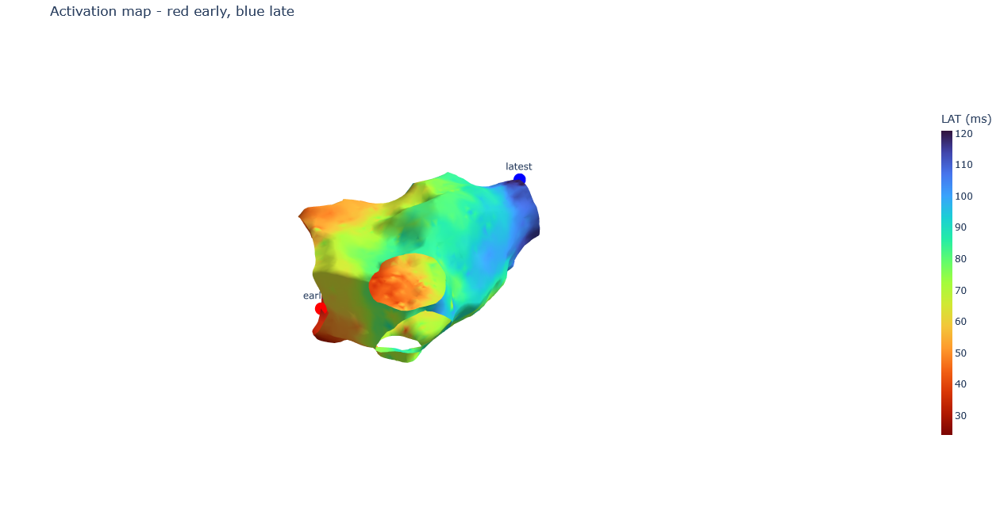

In [25]:
activation = mesh_to_plotly(
    points, triangles, scalars=vertex_lat, colorscale="Turbo_r",
    colorbar_title="LAT (ms)", name="activation",
)

extremes = go.Scatter3d(
    x=points[[earliest_vertex, latest_vertex], 0],
    y=points[[earliest_vertex, latest_vertex], 1],
    z=points[[earliest_vertex, latest_vertex], 2],
    mode="markers+text",
    marker=dict(size=9, color=["red", "blue"]),
    text=["earliest", "latest"], textposition="top center", name="extremes",
)

plotly_figure([activation, extremes], title="Activation map - red early, blue late").show()

### Reading it

- **Focal pattern** — activation radiates outward from one early site, like a
  stone dropped in water. The earliest point is the source, and it is the ablation
  target.
- **Macro-reentrant pattern** — the earliest and latest regions sit *adjacent* to
  each other, with colour sweeping through the full cycle in between. Early meets
  late because the wave never stops; it circulates. The target is not a point but
  the narrow isthmus the circuit depends on.

The distinction is the central diagnostic question in an ablation procedure, and
it is answered by looking at this picture.

Total activation time carries the same information numerically: if it approaches
the full cycle length, the chamber is never electrically quiet, which means the
wavefront is continuously circulating — reentry.

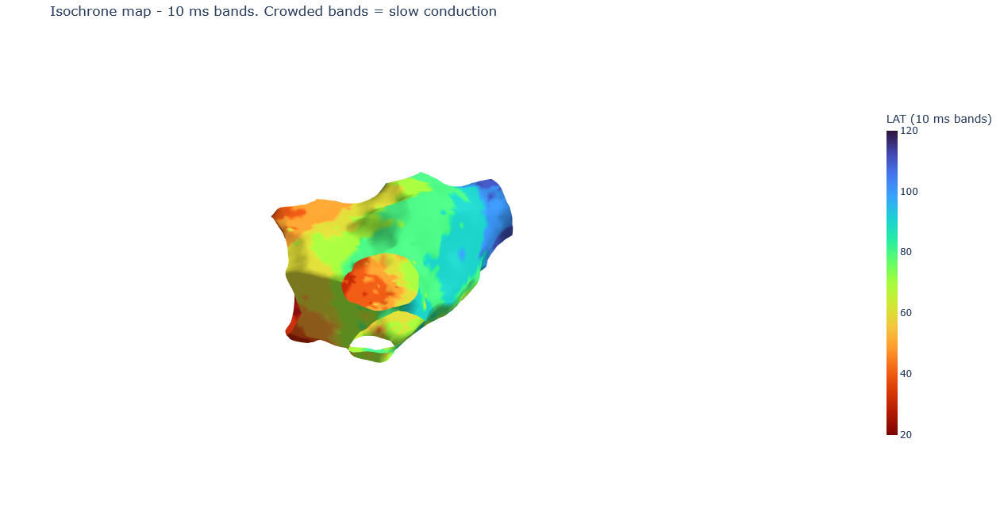

In [26]:
# DERIVED. Isochrones make crowding visible: tight bands mean slow conduction.
isochrone_step = 10  # ms
banded = np.floor(vertex_lat / isochrone_step) * isochrone_step

plotly_figure(
    [mesh_to_plotly(points, triangles, scalars=banded, colorscale="Turbo_r",
                    colorbar_title=f"LAT ({isochrone_step} ms bands)")],
    title=f"Isochrone map - {isochrone_step} ms bands. Crowded bands = slow conduction",
).show()

## Part 6 — Voltage: mapping the substrate

Timing tells you how the wave moved. **Amplitude tells you what the tissue is.**

Healthy myocardium depolarises in bulk and synchronously, producing a large sharp
bipolar deflection. Scar has fewer surviving myocytes, so it generates less
signal. Bipolar peak-to-peak voltage therefore acts as a proxy for viable tissue,
and the clinical thresholds are well established for atrial tissue:

| Bipolar voltage | Interpretation |
|---|---|
| < 0.5 mV | dense scar |
| 0.5 - 1.5 mV | border zone / diseased |
| > 1.5 mV | healthy myocardium |

These are conventions calibrated against imaging and outcomes, not laws of
physics — but they drive real clinical decisions.

In [27]:
# DERIVED, cross-checked against the system's stored values.
our_voltage = np.full(electric.n_points, np.nan)
for i in range(electric.n_points):
    start = int(reference_annotation[i] + woi[i, 0])
    stop = int(reference_annotation[i] + woi[i, 1])
    start, stop = max(start, 0), min(stop, electric.n_samples)
    if stop - start < 2:
        continue
    segment = stored_bipolar[i, start:stop]
    our_voltage[i] = np.nanmax(segment) - np.nanmin(segment)

stored_voltage = electric.bipolar_egm.voltage
comparable = np.isfinite(our_voltage) & np.isfinite(stored_voltage)

print(f"our peak-to-peak    : {np.nanmedian(our_voltage):.3f} mV median")
print(f"system's value      : {np.nanmedian(stored_voltage):.3f} mV median")
print(f"correlation         : {np.corrcoef(our_voltage[comparable], stored_voltage[comparable])[0, 1]:.4f}")
print(f"median |difference| : {np.nanmedian(np.abs(our_voltage[comparable] - stored_voltage[comparable])):.3f} mV")

our peak-to-peak    : 2.271 mV median
system's value      : 2.271 mV median
correlation         : 1.0000
median |difference| : 0.000 mV


In [28]:
# DERIVED. Interpolate voltage onto the shell and classify tissue.
vertex_voltage = interpolate_to_surface(surface_points, stored_voltage, points)

vertex_area = np.zeros(len(points))
np.add.at(vertex_area, triangles.ravel(), np.repeat(areas / 3.0, 3))

mapped = np.isfinite(vertex_voltage)
total_area = vertex_area[mapped].sum()

categories = [
    ("dense scar (<0.5 mV)", mapped & (vertex_voltage < 0.5)),
    ("border (0.5-1.5 mV)", mapped & (vertex_voltage >= 0.5) & (vertex_voltage < 1.5)),
    ("healthy (>1.5 mV)", mapped & (vertex_voltage >= 1.5)),
]

print(f"{'category':<24}{'vertices':>10}{'area mm^2':>12}{'share':>9}")
for label, mask in categories:
    area = vertex_area[mask].sum()
    print(f"{label:<24}{int(mask.sum()):>10}{area:>12,.0f}{area / total_area * 100:>8.1f}%")
print(f"\n{'unmapped':<24}{int((~mapped).sum()):>10}")

category                  vertices   area mm^2    share
dense scar (<0.5 mV)           210         446     4.0%
border (0.5-1.5 mV)           1626       2,395    21.6%
healthy (>1.5 mV)             5243       8,254    74.4%

unmapped                      2200


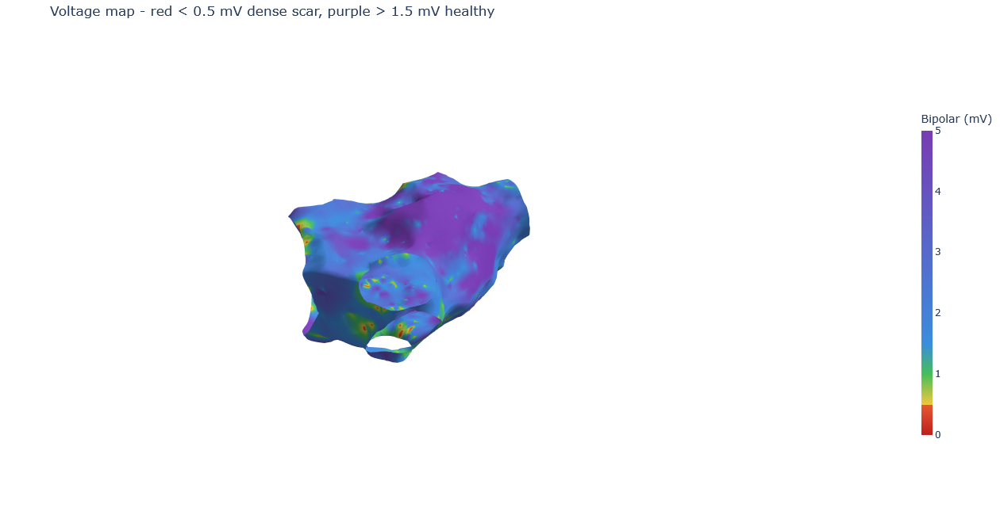

In [29]:
voltage_map = mesh_to_plotly(
    points, triangles, scalars=np.clip(vertex_voltage, 0, 5.0),
    colorscale=epkit.voltage_colorscale(), cmin=0.0, cmax=5.0,
    colorbar_title="Bipolar (mV)", name="voltage",
)
plotly_figure([voltage_map],
              title="Voltage map - red < 0.5 mV dense scar, purple > 1.5 mV healthy").show()

### The catch: bipolar voltage depends on wavefront direction

Part 2 established that a bipolar signal is the difference between two electrodes
— a spatial derivative along the axis joining them. A derivative along an axis is
maximal when the wavefront travels **along** that axis and vanishes when it
travels **perpendicular** to it.

So identical healthy tissue can read as low voltage purely because of the angle
the catheter happened to sit at. Some low-voltage regions on any bipolar map are
not scar; they are geometry.

Testing this needs two vectors: the **bipole axis** (the line joining the two
electrodes) and the **wavefront direction** at that spot. We have the first
already — `egmUniX` stores both unipolar electrode positions.

In [30]:
# MEASURED. The bipole axis, recovered from the two unipolar electrode positions.
electrode_positions = electric.unipolar_egm.points        # (n_points, 3, 2)
bipole_axis = electrode_positions[:, :, 0] - electrode_positions[:, :, 1]
electrode_separation = np.linalg.norm(bipole_axis, axis=1)

print(f"electrode separation: median {np.nanmedian(electrode_separation):.2f} mm "
      f"(p5 {np.nanpercentile(electrode_separation, 5):.2f}, "
      f"p95 {np.nanpercentile(electrode_separation, 95):.2f})")
print("consistent with the 2 mm spacing of a 20-pole mapping catheter.")

bipole_axis = bipole_axis / np.linalg.norm(bipole_axis, axis=1, keepdims=True)

electrode separation: median 1.98 mm (p5 1.78, p95 2.00)
consistent with the 2 mm spacing of a 20-pole mapping catheter.


The second vector — wavefront direction — is exactly what conduction velocity
gives us, so this test has to wait for Part 7. We will come back to it.

**A warning about a tempting shortcut.** The file has a `barDirection` field, and
its name invites you to read it as the electrode orientation. It is not: OpenEP
loads it as `electric.surface.normals`, the *surface normal* at each point. Test
one against the other and you get an alignment of exactly 1.000 at every point,
because they are the same array. A field name is not a specification.

## Part 7 — Conduction velocity

We have a scalar timing field across a surface. Its **gradient** tells us how
fast and in which direction the wave moved.

If activation time is $t(\mathbf{x})$ in ms and position is in mm, then
$|\nabla t|$ has units ms/mm — the time cost per millimetre travelled. Speed is
its reciprocal:

$$\mathrm{CV} = \frac{1}{|\nabla t|}$$

with the wave travelling along $+\nabla t$, toward later activation. On a
triangulated surface the gradient is computed per triangle: a linear field over
a triangle has a constant gradient, obtained by solving the two edge equations
together with the constraint that the gradient lies in the triangle plane. We
then average onto vertices.

`openep-py` has **no conduction-velocity function at all**, so there is nothing
to check against. Instead the implementation is validated in the test suite
against a synthetic planar wave with a known answer: a wave at 1 mm/ms must come
back as exactly 1000 mm/s. That test passes, so the code below is trustworthy.

Normal atrial conduction is roughly **600-1200 mm/s**. Below ~300 mm/s is slow
conduction — the substrate that sustains reentry.

vertices with CV : 5,430
median CV        : 759 mm/s
IQR              : 440 to 1,413 mm/s
slow (<300 mm/s) : 11.8% of mapped surface
implausible (>2 m/s) : 15.4%


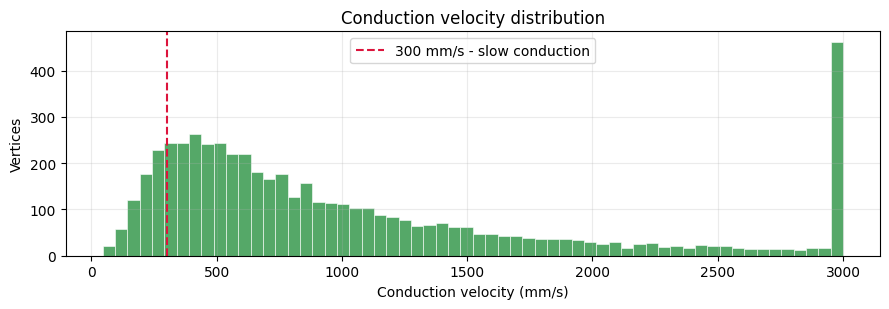

In [31]:
# DERIVED. Conduction velocity from the interpolated activation field.
cv_speed, cv_direction = epkit.conduction_velocity(points, triangles, vertex_lat)

finite_cv = cv_speed[np.isfinite(cv_speed)]
print(f"vertices with CV : {finite_cv.size:,}")
print(f"median CV        : {np.median(finite_cv):,.0f} mm/s")
print(f"IQR              : {np.percentile(finite_cv, 25):,.0f} to {np.percentile(finite_cv, 75):,.0f} mm/s")
print(f"slow (<300 mm/s) : {np.mean(finite_cv < 300) * 100:.1f}% of mapped surface")
print(f"implausible (>2 m/s) : {np.mean(finite_cv > 2000) * 100:.1f}%")

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.hist(np.clip(finite_cv, 0, 3000), bins=60, color="#55a868", edgecolor="white", lw=0.4)
ax.axvline(300, color="crimson", ls="--", label="300 mm/s - slow conduction")
ax.set_xlabel("Conduction velocity (mm/s)")
ax.set_ylabel("Vertices")
ax.set_title("Conduction velocity distribution")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

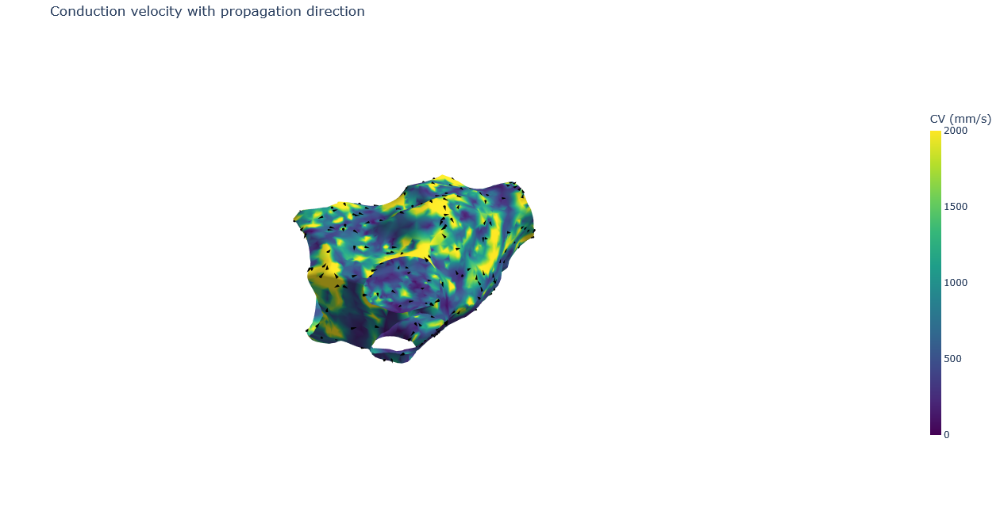

In [32]:
cv_display = np.clip(cv_speed, 0, 2000)
cv_map = mesh_to_plotly(
    points, triangles, scalars=cv_display, colorscale="Viridis",
    cmin=0, cmax=2000, colorbar_title="CV (mm/s)", name="conduction velocity",
)

step = max(len(points) // 400, 1)
sample = np.arange(0, len(points), step)
sample = sample[np.isfinite(cv_direction[sample]).all(axis=1)]
arrow_scale = 3.0

arrows = go.Cone(
    x=points[sample, 0], y=points[sample, 1], z=points[sample, 2],
    u=cv_direction[sample, 0] * arrow_scale,
    v=cv_direction[sample, 1] * arrow_scale,
    w=cv_direction[sample, 2] * arrow_scale,
    sizemode="absolute", sizeref=4.0, showscale=False,
    colorscale=[[0, "black"], [1, "black"]], name="propagation",
)

plotly_figure([cv_map, arrows],
              title="Conduction velocity with propagation direction").show()

### When conduction velocity lies

CV is the most derived quantity in this notebook — a numerical gradient of an
interpolated field built from annotated timings. Every one of those layers can
inject error, and three situations produce confidently wrong numbers:

- **Wave collision.** Where two wavefronts meet, timing has a genuine
  discontinuity. The gradient there is huge and the computed CV drops toward
  zero, mimicking slow conduction that does not exist.
- **Breakthrough.** Where a wave emerges from a different plane, the surface
  gradient near-vanishes and CV goes implausibly high — which is exactly what the
  implausible fraction printed above is measuring.
- **Sparse sampling.** Where the interpolator invented the field, the gradient
  describes the interpolator, not the tissue.

Cross-reference the CV map against the coverage map from Part 3 and the voltage
map above before believing any specific slow-conduction region.

### Back to Part 6: does bipolar voltage really depend on direction?

Now we have both vectors. For each mapping point, take the bipole axis and the
local propagation direction, and measure their alignment as $|\cos\theta|$: 1 when
the wave travels along the electrode pair, 0 when it crosses perpendicular.

Theory predicts higher bipolar voltage at high alignment.

In [33]:
# DERIVED. Bipole-axis vs wavefront alignment, against measured voltage.
from scipy import stats

nearest_vertex = spatial.cKDTree(points).query(surface_points, k=1)[1]
wavefront = cv_direction[nearest_vertex]

alignment = np.abs(np.sum(bipole_axis * wavefront, axis=1))
usable = np.isfinite(alignment) & np.isfinite(stored_voltage)

lower, upper = np.nanpercentile(alignment[usable], [33, 67])
a, v = alignment[usable], stored_voltage[usable]

print(f"usable points : {int(usable.sum())}")
print(f"{'group':<30}{'n':>6}{'median mV':>12}")
for label, mask in [
    ("perpendicular (align < 0.39)", a <= lower),
    ("intermediate", (a > lower) & (a < upper)),
    ("parallel (align > 0.74)", a >= upper),
]:
    print(f"{label:<30}{int(mask.sum()):>6}{np.nanmedian(v[mask]):>12.3f}")

rho, p_value = stats.spearmanr(a, v)
print(f"\nSpearman rho = {rho:.3f}, p = {p_value:.3g}")

usable points : 1366
group                              n   median mV
perpendicular (align < 0.39)     451       2.160
intermediate                     464       2.279
parallel (align > 0.74)          451       2.301

Spearman rho = 0.056, p = 0.0383


The effect is **there, in the predicted direction, and small**: about 2.16 mV
when the wave crosses the bipole perpendicular against 2.30 mV when it runs
along it — roughly 7%.

Be careful how you read that p-value. With 1,366 points, a correlation of
$\rho = 0.056$ clears the conventional significance bar while explaining well
under 1% of the variance in voltage. **Statistically detectable and clinically
negligible are different claims**, and this is a clean example of the gap.

So the honest conclusion is narrower than the textbook warning implies: direction
dependence is real and measurable here, but in this dataset it is not what
separates a 0.3 mV scar reading from a 2 mV healthy one. Tissue is doing most of
the work. The mechanism still matters — it is why unipolar voltage, which has no
directional axis, is read alongside bipolar — but on this evidence it is a
second-order correction, not a reason to distrust the substrate map.

Two caveats keep even that modest conclusion tentative. The propagation direction
is itself derived from an interpolated field, so it carries all of Part 4's
uncertainty. And it describes the mapped beat, whereas each point was recorded at
a different moment, potentially under a different activation pattern.

## Part 8 — Ablation: delivering and recording therapy

Diagnosis identifies the target; **ablation** destroys it. A radiofrequency
catheter passes current into the tissue, heating it resistively. Above roughly
50 °C myocytes die and are replaced by scar, which is electrically inert — and
that is the point. A well-placed line of lesions blocks the circuit.

The export claims to record power, impedance, temperature, and contact force
throughout. Before plotting any of it, check whether the numbers are physically
possible — the same discipline Part 2 applied to the electrograms.

In [34]:
# MEASURED - and audited before use.
ablation = case.ablation
force = ablation.force

channels = [
    ("power (W)", np.asarray(ablation.power, float), 0, 60),
    ("temperature (C)", np.asarray(ablation.temperature, float), 30, 65),
    ("impedance (ohm)", np.asarray(ablation.impedance, float), 50, 300),
    ("contact force (g)", np.asarray(force.force, float), 0, 60),
]

print(f"RF samples: {len(ablation.times):,}   force samples: {len(force.times):,}\n")
print(f"{'channel':<20}{'min':>10}{'max':>12}{'plausible range':>20}   verdict")
for label, series, low, high in channels:
    finite = series[np.isfinite(series)]
    ok = finite.size and (finite.max() <= high * 1.5) and (finite.max() > low)
    verdict = "usable" if ok else "NOT POPULATED"
    print(f"{label:<20}{np.nanmin(finite):>10.1f}{np.nanmax(finite):>12.1f}"
          f"{f'{low}-{high}':>20}   {verdict}")

impedance = np.asarray(ablation.impedance, float)
print(f"\nimpedance, first 6 samples: {impedance[:6]}")
print(f"consecutive differences   : {np.diff(impedance[:6])}")

RF samples: 17,258   force samples: 34,193

channel                    min         max     plausible range   verdict
power (W)                  0.0         0.0                0-60   NOT POPULATED
temperature (C)            3.0        31.0               30-65   usable
impedance (ohm)         2000.0     44600.0              50-300   NOT POPULATED
contact force (g)          0.0        43.8                0-60   usable

impedance, first 6 samples: [2000. 2100. 2200. 2300. 2400. 2500.]
consecutive differences   : [100. 100. 100. 100. 100.]


Three of the four channels do not survive the check.

**Power is identically zero** across all 17,258 samples. **Impedance** rises in
exact steps of 100 from a round starting value and reaches 44,600 Ω — that is a
counter, not ohms; real catheter impedance sits near 100-150 Ω.
**Temperature** never exceeds 31 °C, which is below body temperature, let alone
the ~50 °C needed to kill myocytes. Dataset 2 shows the identical pattern, so
this is a systematic property of the export rather than a corrupt file.

**Contact force is real** — 0.04 to 43.8 g is exactly the expected range.

Had we plotted the impedance channel without looking, we would have produced a
clean rising line and could have narrated it as a lesion-formation signal. It
would have been pure fiction. This is what "verify, don't assume" costs and buys.

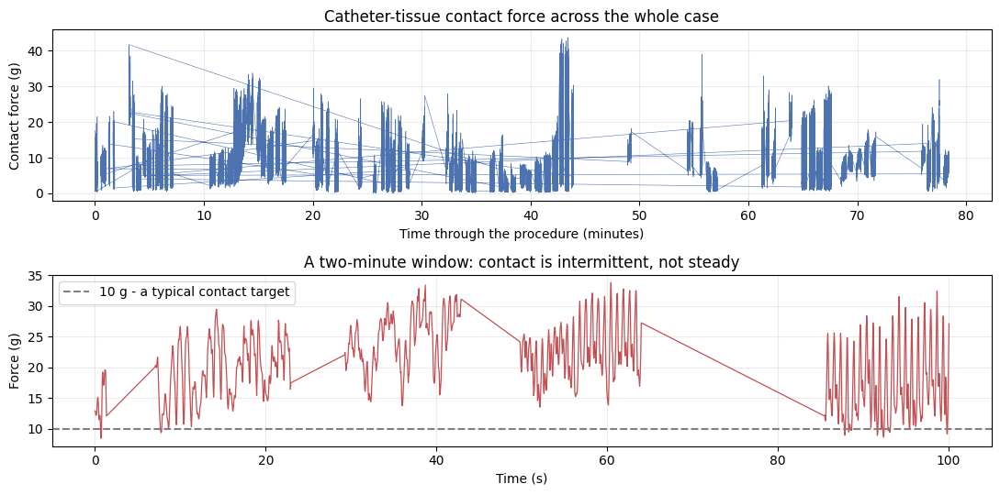

median force while in contact (>1 g): 7.5 g
share of samples below 5 g          : 32.7%


In [35]:
# MEASURED. Contact force is the one raw channel worth plotting.
force_time = (np.asarray(force.times, float) - force.times[0]) / 1000.0
force_values = np.asarray(force.force, float)

fig, axes = plt.subplots(2, 1, figsize=(11, 5.5))
axes[0].plot(force_time / 60.0, force_values, lw=0.4, color="#4c72b0")
axes[0].set_xlabel("Time through the procedure (minutes)")
axes[0].set_ylabel("Contact force (g)")
axes[0].set_title("Catheter-tissue contact force across the whole case")
axes[0].grid(alpha=0.25)

busiest = int(np.argmax(np.convolve(force_values, np.ones(600) / 600, mode="same")))
window = slice(max(busiest - 600, 0), min(busiest + 600, len(force_values)))
axes[1].plot(force_time[window] - force_time[window][0], force_values[window],
             lw=0.9, color="#c44e52")
axes[1].axhline(10, color="grey", ls="--", label="10 g - a typical contact target")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Force (g)")
axes[1].set_title("A two-minute window: contact is intermittent, not steady")
axes[1].legend()
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()

print(f"median force while in contact (>1 g): "
      f"{np.nanmedian(force_values[force_values > 1]):.1f} g")
print(f"share of samples below 5 g          : "
      f"{np.mean(force_values < 5) * 100:.1f}%")

Contact is intermittent and often light — which is precisely why force-aware
lesion metrics were invented.

### Lesion tags: what the operator left behind

Each completed lesion is recorded as a **tag** — a marked position with the
metrics describing lesion quality. `openep-py` does not load these (its
documentation says so explicitly), so we parse them ourselves.

In [36]:
# MEASURED. The ablation lesion tags, parsed directly from rfindex.
tags = epkit.load_rfindex(1)

print(f"lesion tags : {len(tags)}")
print(f"index metric: {tags.index_name}")
print()
print(f"{'metric':<24}{'median':>10}{'min':>10}{'max':>10}")
for label, values in [
    ("duration (s)", tags.duration),
    ("average force (g)", tags.avg_force),
    ("max power (W)", tags.max_power),
    ("max temperature (C)", tags.max_temp),
    ("force-time integral (gs)", tags.fti),
]:
    print(f"{label:<24}{np.nanmedian(values):>10.1f}"
          f"{np.nanmin(values):>10.1f}{np.nanmax(values):>10.1f}")

lesion tags : 90
index metric: AblationIndex

metric                      median       min       max
duration (s)                  18.0       3.9      35.5
average force (g)              8.5       3.2      26.7
max power (W)                 31.0      30.5      31.5
max temperature (C)           33.4      31.6      37.6
force-time integral (gs)     154.0      16.0     327.0


Note what just happened. The raw telemetry was mostly unusable, but the
**per-lesion summaries are intact and physically sensible**: about 31 W of power,
a peak temperature in the mid-30s, 8.5 g of average contact, and lesion durations
of 4-36 seconds. The mapping system computed and stored these at the time; the
underlying sample streams simply were not exported. Summary survived, raw did not.

**Force-time integral (FTI)** is the product of contact force and duration —
grams-seconds. It exists because lesion depth depends on how hard the catheter
pressed and for how long, not merely on power. Poor contact means a superficial
lesion that looks identical on the map and recovers weeks later.

**Ablation Index** — the `index` field, and the metric this case was actually
guided by — goes further, combining force, power, and time in a weighted formula
fitted to observed lesion depth. It is the number many operators watch in real
time, with targets that differ by wall thickness (commonly around 350-400 on the
posterior wall, higher anteriorly, where tissue is thicker).

That matters because durability is the central failure mode of atrial
fibrillation ablation: pulmonary vein reconnection. A substantial share of
patients need a repeat procedure, and reconnected gaps in an ablation line are
the usual reason. These indices exist to predict which lesions will hold.

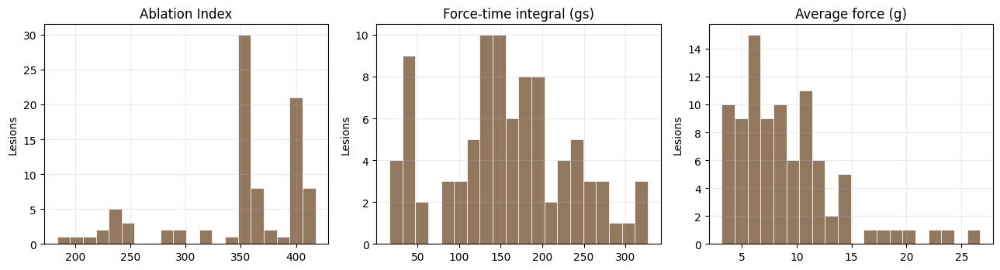

Ablation Index vs FTI, Spearman rho = 0.901
Related but not identical - the index weights power and time differently.


In [37]:
# MEASURED. Ablation Index against its components.
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (label, values) in zip(axes, [
    ("Ablation Index", tags.index_value),
    ("Force-time integral (gs)", tags.fti),
    ("Average force (g)", tags.avg_force),
]):
    ax.hist(values[np.isfinite(values)], bins=20, color="#937860",
            edgecolor="white", lw=0.5)
    ax.set_title(label)
    ax.set_ylabel("Lesions")
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

usable_tags = np.isfinite(tags.index_value) & np.isfinite(tags.fti)
rho_index, _ = stats.spearmanr(tags.index_value[usable_tags], tags.fti[usable_tags])
print(f"Ablation Index vs FTI, Spearman rho = {rho_index:.3f}")
print("Related but not identical - the index weights power and time differently.")

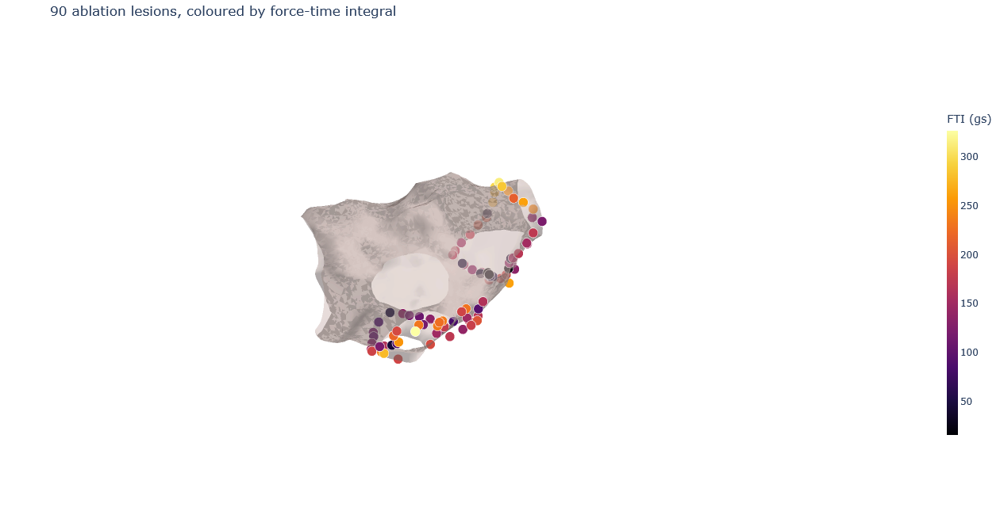

In [38]:
# MEASURED. Lesion tags on the anatomy, coloured by force-time integral.
shell_faint = mesh_to_plotly(points, triangles, name="shell", opacity=0.55, showscale=False)

lesions = go.Scatter3d(
    x=tags.points[:, 0], y=tags.points[:, 1], z=tags.points[:, 2],
    mode="markers",
    marker=dict(
        size=7, color=tags.fti, colorscale="Inferno", showscale=True,
        colorbar=dict(title="FTI (gs)", thickness=14, len=0.7),
        line=dict(width=0.5, color="white"),
    ),
    text=[f"lesion {i}: {f:.0f} gs, {d:.1f} s, {p:.0f} W"
          for i, (f, d, p) in enumerate(zip(tags.fti, tags.duration, tags.max_power))],
    hoverinfo="text", name="lesions",
)

plotly_figure([shell_faint, lesions],
              title=f"{len(tags)} ablation lesions, coloured by force-time integral").show()

### Tagging in general

"Tag" covers three different things in an EP lab, and it is worth separating them:

| Kind | What it marks | In this data |
|---|---|---|
| **Ablation tags** | where therapy was delivered | **90, with full metrics** |
| **Anatomical / landmark tags** | vein ostia, valve, phrenic nerve capture | `landmark_points` field exists |
| **Point tags** | electrogram features: fractionated, double potential, late potential | field exists, **empty in this export** |

That last row is the honest gap. `electric.tags` is present in the OpenEP schema
and empty in both datasets — the operator's annotations did not survive the
export. Rather than skip the topic, we can detect the features ourselves.

**Fractionated** electrograms show many small deflections instead of one sharp
spike, marking slow disorganised conduction through surviving muscle strands
inside scar. Those regions are ablation targets in their own right.

In [39]:
# Confirming the gap rather than asserting it.
print("does the loaded object even expose tags? ",
      hasattr(electric, "tags"))

raw_tags = raw["userdata"][0, 0]["electric"][0, 0]["tags"].ravel()
tag_values = [
    str(np.asarray(t).ravel()[0]) if np.asarray(t).size else "" for t in raw_tags
]
non_empty = [t for t in tag_values if t.strip() not in ("", "[]")]

print(f"tag entries in the raw file : {len(tag_values)}")
print(f"non-empty tags              : {len(non_empty)}")
print(f"point labels that DID survive: {list(electric.internal_names[:6])} ...")

does the loaded object even expose tags?  False
tag entries in the raw file : 1366
non-empty tags              : 0
point labels that DID survive: ['P9', 'P10', 'P11', 'P12', 'P13', 'P14'] ...


The field exists in the MATLAB file, carries one entry per point, and every entry
is empty — and `openep-py` does not even surface it as an attribute. The point
labels (`P9`, `P10`, …) survived; the operator's clinical annotations did not.

deflection count: median 2.0, 90th percentile 5.0
flagged as complex: 155 of 1366 points


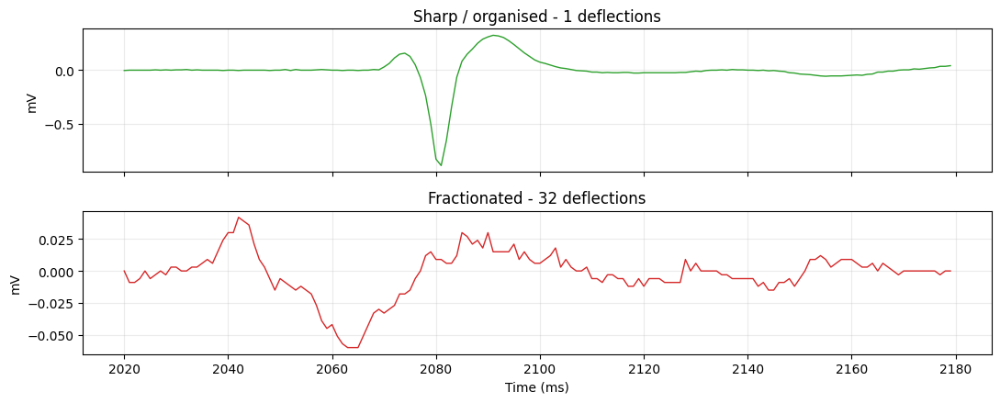

In [40]:
# DERIVED. Detect fractionation ourselves, since the operator's tags are absent.
window_samples = (int(reference_annotation[0] + woi[0, 0]),
                  int(reference_annotation[0] + woi[0, 1]))
deflections = epkit.fractionation_index(stored_bipolar, electric.frequency, window_samples)

threshold = np.nanpercentile(deflections, 90)
complex_points = deflections >= threshold
print(f"deflection count: median {np.nanmedian(deflections):.1f}, "
      f"90th percentile {threshold:.1f}")
print(f"flagged as complex: {int(complex_points.sum())} of {len(deflections)} points")

simple_idx = int(np.nanargmin(np.where(np.isfinite(deflections), deflections, np.inf)))
complex_idx = int(np.nanargmax(np.where(np.isfinite(deflections), deflections, -np.inf)))

fig, axes = plt.subplots(2, 1, figsize=(11, 4.5), sharex=True)
sl = slice(*window_samples)
axes[0].plot(times_ms[sl], stored_bipolar[simple_idx, sl], color="#2ca02c", lw=1.0)
axes[0].set_title(f"Sharp / organised - {deflections[simple_idx]:.0f} deflections")
axes[1].plot(times_ms[sl], stored_bipolar[complex_idx, sl], color="#d62728", lw=1.0)
axes[1].set_title(f"Fractionated - {deflections[complex_idx]:.0f} deflections")
axes[1].set_xlabel("Time (ms)")
for ax in axes:
    ax.set_ylabel("mV")
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [41]:
# DERIVED. Do our complex points agree with low voltage, as theory predicts?
comparable_pts = np.isfinite(deflections) & np.isfinite(stored_voltage)
print(f"median voltage, flagged complex : "
      f"{np.nanmedian(stored_voltage[complex_points & comparable_pts]):.3f} mV")
print(f"median voltage, rest            : "
      f"{np.nanmedian(stored_voltage[~complex_points & comparable_pts]):.3f} mV")
rho_frac, p_frac = stats.spearmanr(
    deflections[comparable_pts], stored_voltage[comparable_pts]
)
print(f"Spearman rho (deflections vs voltage) = {rho_frac:.3f}, p = {p_frac:.3g}")

median voltage, flagged complex : 0.501 mV
median voltage, rest            : 2.550 mV
Spearman rho (deflections vs voltage) = -0.564, p = 1.47e-115


This is the strongest validation in the notebook, and we got it for free.

Nothing in the fractionation detector knows anything about voltage — it only
counts deflections in a waveform. Yet the points it flags have a median voltage
of **0.50 mV against 2.55 mV** for everything else, sitting exactly on the dense-scar
threshold from Part 6, with a correlation of $\rho = -0.56$ across 1,366 points.

Two independent measurements of tissue health — *how fragmented is the signal*
and *how large is the signal* — agree. That is what a real physiological
relationship looks like, and it is worth contrasting with the direction-dependence
result in Part 7, where $\rho = 0.056$ was statistically significant and
practically meaningless. Same test, same dataset, effect sizes two orders of
magnitude apart.

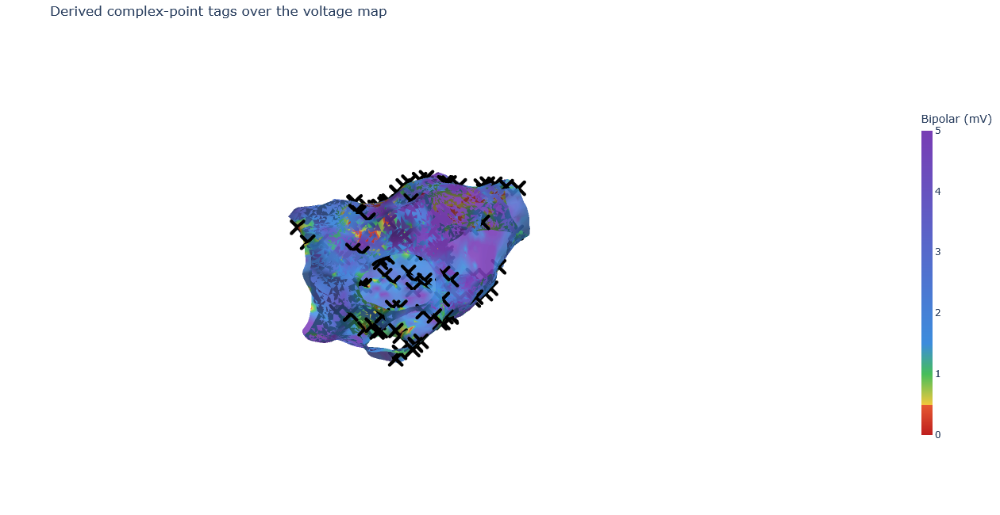

In [42]:
# DERIVED. Our own complex-point tags on the anatomy.
flagged = complex_points & np.isfinite(surface_points).all(axis=1)
voltage_shell = mesh_to_plotly(
    points, triangles, scalars=np.clip(vertex_voltage, 0, 5.0),
    colorscale=epkit.voltage_colorscale(), cmin=0, cmax=5.0,
    colorbar_title="Bipolar (mV)", opacity=0.9,
)
flags = go.Scatter3d(
    x=surface_points[flagged, 0], y=surface_points[flagged, 1],
    z=surface_points[flagged, 2],
    mode="markers", marker=dict(size=5, color="black", symbol="x"),
    name="derived complex points",
)
plotly_figure([voltage_shell, flags],
              title="Derived complex-point tags over the voltage map").show()

## Part 9 — The workflow this data came from

The arrays we have been reading are the residue of a procedure that runs roughly
like this:

1. **Access** — catheters to the chamber; for the left atrium, across the septum.
2. **Geometry (FAM)** — sweep the chamber to build the shell (Part 3).
3. **Mapping** — collect electrograms across the surface (Parts 2, 4, 5, 6).
4. **Diagnosis** — read the activation and voltage maps; focal or reentrant?
5. **Pace mapping / entrainment** — confirm the mechanism and target.
6. **Ablation** — deliver lesions, tag them (Part 8).
7. **Validation** — remap to prove the target is gone, and wait to check durability.

### Point-by-point vs continuous acquisition

Two ways to collect step 3.

**Point-by-point** — position the catheter, confirm contact and stability, accept
one point. Slow, deliberate, every point reviewed by a human. Hundreds of points.

**Continuous / pattern acquisition** — a multipolar catheter with many electrodes
sweeps while the system automatically accepts everything meeting quality criteria.
Thousands to tens of thousands of points, no human reviewing each one.

The acquisition mode is not stored in the export, but it leaves fingerprints.

In [43]:
# DERIVED. Fingerprints of how the data was collected.
catheter_names = raw["userdata"][0, 0]["electric"][0, 0]["electrodeNames_bip"]
labels = [
    str(np.asarray(n).ravel()[0]) if np.asarray(n).size else ""
    for n in catheter_names.ravel()
]
unique_labels, counts = np.unique(labels, return_counts=True)

print("Electrode channels contributing points:")
for label, count in sorted(zip(unique_labels, counts), key=lambda pair: -pair[1]):
    print(f"  {label:<14}{count:>6} points")

print(f"\ndistinct electrode pairs : {len(unique_labels)}")
print(f"points per pair          : {np.median(counts):.0f} median")
print(f"total points             : {electric.n_points}")

Electrode channels contributing points:
  20A_9-10         197 points
  20A_5-6          177 points
  20A_13-14        150 points
  20A_11-12        146 points
  20A_17-18        146 points
  20A_15-16        125 points
  20A_1-2          119 points
  20A_19-20        114 points
  20A_3-4           97 points
  20A_7-8           95 points

distinct electrode pairs : 10
points per pair          : 136 median
total points             : 1366


Ten bipolar channels named `20A_1-2` through `20A_19-20`: a **20-pole circular
mapping catheter**, collecting through ten electrode pairs at once. With the
points spread fairly evenly across those ten channels, this was multi-electrode
acquisition — not one-point-at-a-time. That is the acquisition mode, recovered
from electrode naming alone.

It also explains the clustering we found in Part 3: ten electrodes firing
together drop ten points within a couple of millimetres of each other, which is
why nearest-neighbour spacing looked so much better than actual surface coverage.

### Pace mapping and PASO

When activation mapping cannot localise a focal source — often because the
arrhythmia is infrequent and will not stay running long enough to map — the logic
gets inverted. Instead of recording where the wave went, **pace from a candidate
site and see whether the resulting body-surface ECG matches the clinical
arrhythmia.**

If pacing from a site reproduces the arrhythmia's 12-lead morphology, that site
activates the heart the same way the arrhythmia does, so it is at or very near the
source. **PASO** is CARTO's module for this: it correlates the paced 12-lead
complex against a stored template and reports a percentage, typically calling
> 95% across all twelve leads a good match.

**This dataset cannot reproduce PASO.** It stores a *single* ECG channel, not
twelve, and no paced templates. What follows demonstrates the correlation
mathematics on the one lead available — the method, not the clinical tool.

ECG channels available: 1 (['ECG']) - PASO needs 12

template          : point P9
beats compared    : 400
median correlation: 0.989
above 0.95        : 100.0%


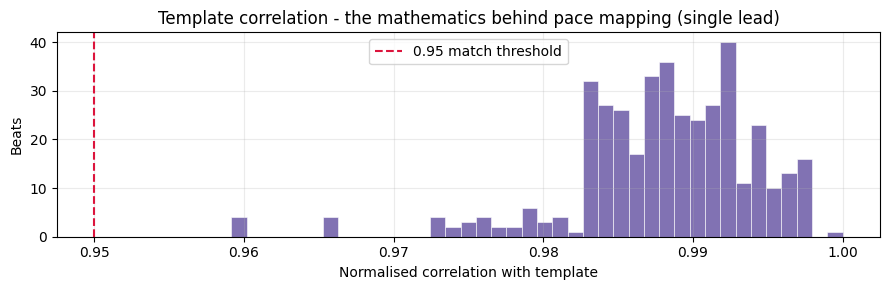

In [44]:
# ILLUSTRATIVE. Normalised cross-correlation of ECG morphology.
# The method behind PASO, on one lead instead of twelve. Not a PASO result.
ecg = electric.ecg.ecg[:, :, 0]
print(f"ECG channels available: {electric.ecg.n_channels} "
      f"({list(electric.ecg.channel_names)}) - PASO needs 12")


def normalised_correlation(a, b):
    a = a - np.nanmean(a)
    b = b - np.nanmean(b)
    denominator = np.sqrt(np.nansum(a ** 2) * np.nansum(b ** 2))
    return np.nansum(a * b) / denominator if denominator > 0 else np.nan


segment = slice(*window_samples)
template = ecg[0, segment]
scores = np.array([
    normalised_correlation(template, ecg[i, segment])
    for i in range(min(400, len(ecg)))
])

print(f"\ntemplate          : point {electric.internal_names[0]}")
print(f"beats compared    : {scores.size}")
print(f"median correlation: {np.nanmedian(scores):.3f}")
print(f"above 0.95        : {np.nanmean(scores > 0.95) * 100:.1f}%")

fig, ax = plt.subplots(figsize=(9, 3))
ax.hist(scores[np.isfinite(scores)], bins=40, color="#8172b3", edgecolor="white", lw=0.4)
ax.axvline(0.95, color="crimson", ls="--", label="0.95 match threshold")
ax.set_xlabel("Normalised correlation with template")
ax.set_ylabel("Beats")
ax.set_title("Template correlation - the mathematics behind pace mapping (single lead)")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

Look at how badly that fails as a discriminator: **100% of beats clear the 0.95
threshold**, with a median correlation of 0.989. If this were PASO, every single
site in the atrium would be declared a perfect match for the arrhythmia origin.

Which is the point. These beats are all the same rhythm in the same patient, and
projected onto one lead they are indistinguishable. A single ECG axis cannot
separate sites whose activation patterns differ in the directions that axis does
not see. Twelve leads sample twelve different directions through the heart, and
that redundancy is the entire source of PASO's specificity.

The arithmetic above is correct and the conclusion you could draw from it would be
worthless — a useful reminder that a validated method applied to insufficient data
still produces confident numbers.

### What can and cannot be reconstructed

**Solid ground — measured directly:**

- Chamber geometry, to about a millimetre, wherever the catheter went.
- Electrogram waveforms at recorded sites, at 1 kHz.
- Activation timing at those sites, subject to the annotation choice.
- Signal amplitude, and therefore a tissue-health proxy.
- Everything about the ablation: position, power, force, temperature, impedance.

**Inference — derived, with real uncertainty:**

- Any value at a vertex that was not measured, which is most of them.
- Conduction velocity: a gradient of an interpolation of annotated timings.
- Scar classification, resting on thresholds and on direction-dependent bipolar
  voltage.
- The arrhythmia mechanism, read from a map built on all of the above.

**Out of reach from this data entirely:**

- Anything transmural. This is a *surface* map; the wall has thickness, and
  circuits can run through it, invisible here.
- Anatomy the catheter never visited.
- True 12-lead pace mapping, and the operator's own point tags.
- What happens after the procedure — durability needs follow-up, not this file.

## Part 10 — Everything at once

Anatomy, activation, substrate, conduction, and therapy — the same chamber under
five different questions. This is what an electrophysiologist is holding in their
head simultaneously while deciding where to ablate.

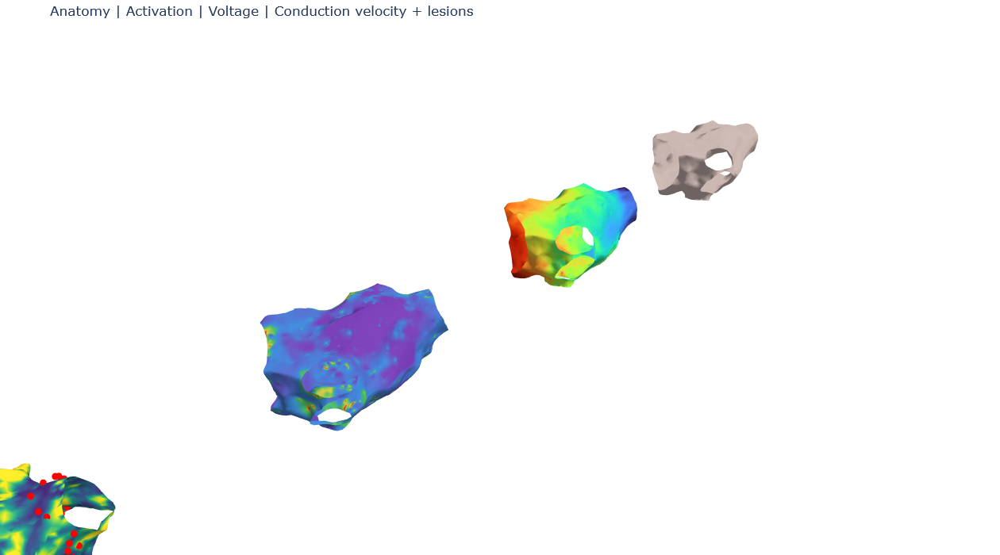

In [45]:
# The full reconstruction, side by side.
spacing = 150.0
panels = [
    ("Anatomy", None, "Greys", None, None),
    ("Activation (ms)", vertex_lat, "Turbo_r",
     float(np.nanmin(vertex_lat)), float(np.nanmax(vertex_lat))),
    ("Voltage (mV)", np.clip(vertex_voltage, 0, 5), epkit.voltage_colorscale(), 0, 5),
    ("Conduction (mm/s)", np.clip(cv_speed, 0, 2000), "Viridis", 0, 2000),
]

panel_traces = []
for offset, (title, field, scale, cmin, cmax) in enumerate(panels):
    shifted = points.copy()
    shifted[:, 0] += offset * spacing
    panel_traces.append(mesh_to_plotly(
        shifted, triangles, scalars=field, colorscale=scale,
        cmin=cmin, cmax=cmax, name=title, showscale=False,
    ))

lesion_panel = go.Scatter3d(
    x=tags.points[:, 0] + 3 * spacing, y=tags.points[:, 1], z=tags.points[:, 2],
    mode="markers", marker=dict(size=5, color="red"), name="lesions",
)

plotly_figure(
    [*panel_traces, lesion_panel],
    title="Anatomy | Activation | Voltage | Conduction velocity + lesions",
    height=700,
).show()

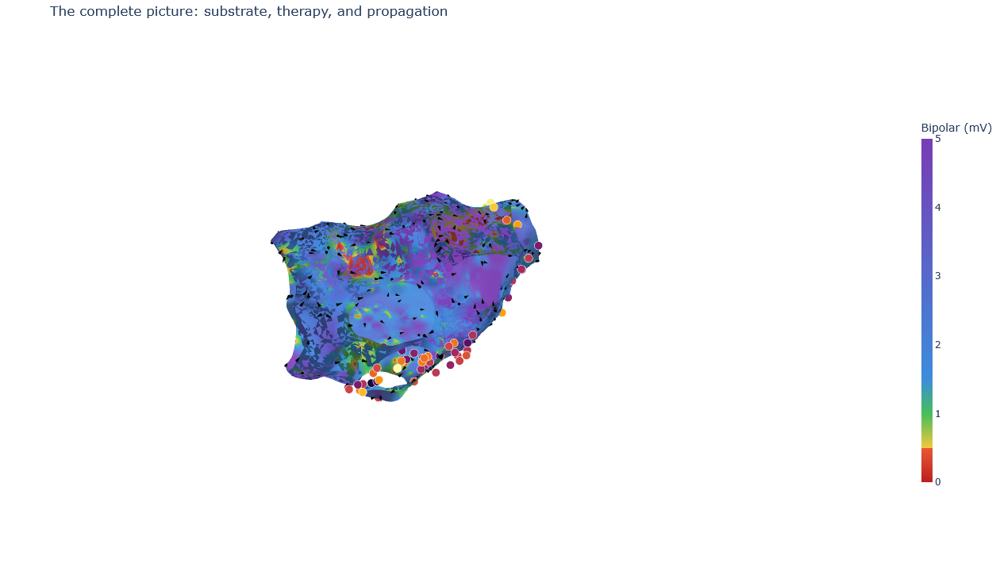

In [46]:
# One interactive view: substrate underneath, lesions on top, propagation arrows.
plotly_figure(
    [
        mesh_to_plotly(points, triangles, scalars=np.clip(vertex_voltage, 0, 5),
                       colorscale=epkit.voltage_colorscale(), cmin=0, cmax=5,
                       colorbar_title="Bipolar (mV)", opacity=0.95),
        go.Scatter3d(
            x=tags.points[:, 0], y=tags.points[:, 1], z=tags.points[:, 2],
            mode="markers",
            marker=dict(size=6, color=tags.fti, colorscale="Inferno",
                        line=dict(width=0.5, color="white")),
            name="ablation lesions",
            text=[f"{f:.0f} gs" for f in tags.fti], hoverinfo="text",
        ),
        arrows,
    ],
    title="The complete picture: substrate, therapy, and propagation",
    height=720,
).show()

## Where to go next

- **[OpenEP](https://openep.io)** — the project these datasets come from; the
  MATLAB implementation is more complete than the Python port.
- **openCARP** — simulate propagation rather than measure it, and test what a
  circuit *would* do.
- **The gaps in this notebook.** Omnipolar mapping addresses the bipolar
  direction-dependence of Part 6. Charge-density and non-contact mapping avoid the
  contact requirement entirely. Ripple mapping abandons annotation — the choice
  Part 2 showed moves the map — by animating raw voltage instead.

**The one thing worth keeping.** Every clinical EP map is a small number of real
measurements, interpolated across a surface, filtered through an annotation
choice, and rendered in colours that imply far more certainty than the underlying
data supports. Knowing which parts are measured and which are inferred is the
whole skill.

Four moments in this notebook made that concrete, and every one was a surprise
that appeared only because we checked the data against what it claimed to be:

- The textbook identity **bipolar = uniA − uniB** did not hold in the file.
- **Nearest-neighbour spacing of 1.5 mm** looked like excellent coverage, while
  40% of the surface was too far from any measurement to colour honestly.
- The `barDirection` field, whose name promises electrode orientation, is the
  **surface normal** — testing it against normals gives 1.000 everywhere.
- Three of the four **RF telemetry channels were never populated**, including an
  "impedance" trace that is a counter incrementing by 100. Plotted without
  checking, it would have made a convincing lesion-formation story.

None of those were visible from the pretty picture. Each was a single line of
verification away.

The habit generalises beyond electrophysiology: **when a field's name makes a
promise, test the promise before you build on it.**